# 02 — Partição supervisionada própria (Fase 2)

> **Aviso:** experimento didático com partição própria; não comparável ao benchmark oficial do MVTec AD.

Este notebook só lê `results/fase2/` (gerado por `python scripts/run_fase2.py`) e explica o que foi feito e por quê. Nada é sorteado nem recalculado aqui.

## 1. Objetivo e pergunta

No MVTec AD as defeituosas só existem na pasta de teste, porque o protocolo oficial é não supervisionado. O projeto precisa de defeituosas para ajustar parâmetros e treinar classificadores, então a partição oficial não serve.

**Pergunta:** como dividir as 292 imagens para que nenhuma decisão seja tomada com as mesmas imagens que depois medem o resultado?

## 2. Hipótese e critério (definidos antes de sortear)

**Hipótese:** com cada imagem em um único papel e validação cruzada estratificada pelo tipo, as comparações das fases seguintes ficam livres de vazamento, mesmo com só ~20 defeituosas por tipo.

**Critérios de aceitação da partição:**

1. Cada imagem tem exatamente um papel; referência e calibração só têm boas do treino; nenhuma boa no desenvolvimento.
2. Cada fold de teste tem todos os tipos de defeito (3 ou 4 imagens de cada) e 15 ou 16 boas.
3. Rodar o script de novo com a mesma semente gera arquivos idênticos.

## 3. O que foi feito

Funções de `pdi_defeitos.split`:

- `make_partition`: sorteia, com a semente do projeto, referência e calibração entre as boas do treino e `n_dev_per_type` defeituosas de cada tipo para o desenvolvimento. O resto vai para a avaliação.
- `check_partition`: recusa a partição se algum critério do item 1 falhar. Um teste em `tests/test_split.py` provoca o vazamento de propósito para confirmar que ele é detectado.
- `make_cv_folds`: `StratifiedKFold` pelo tipo (good e cada defeito), repetido para cada semente.
- `load_partition`: é como as fases seguintes leem `particao.csv`. Elas nunca sorteiam de novo.

Parâmetros usados (do `config.yaml`):

In [ ]:
import pandas as pd
from IPython.display import Image, display
from pdi_defeitos import viz
from pdi_defeitos.config import load_config

cfg = load_config()
res = cfg['root'] / 'results' / 'fase2'

part = pd.read_csv(res / 'particao.csv')
folds = pd.read_csv(res / 'folds.csv')
pd.Series({'seed': cfg['seed'], **cfg['partition']}, name='valor').to_frame()

,valor
seed,0
n_reference,120
n_calibration,30
n_dev_per_type,3
cv_splits,5
cv_seeds,"[0, 1, 2, 3, 4]"


## 4. Resultados

### Partição por papel × tipo

In [ ]:
PAPEIS = {'reference': 'Referência', 'calibration': 'Calibração', 'development': 'Desenvolvimento', 'evaluation': 'Avaliação'}
TIPOS = ['good', 'broken_large', 'broken_small', 'contamination']

tabela = pd.crosstab(part.role, part.defect_type).reindex(index=list(PAPEIS), columns=TIPOS).rename(index=PAPEIS)
tabela.index.name, tabela.columns.name = 'papel', None
tabela.assign(total=tabela.sum(axis=1)).pipe(lambda t: pd.concat([t, t.sum().rename('Total').to_frame().T]))

,good,broken_large,broken_small,contamination,total
Referência,120,0,0,0,120
Calibração,30,0,0,0,30
Desenvolvimento,0,3,3,3,9
Avaliação,79,17,19,18,133
Total,229,20,22,21,292


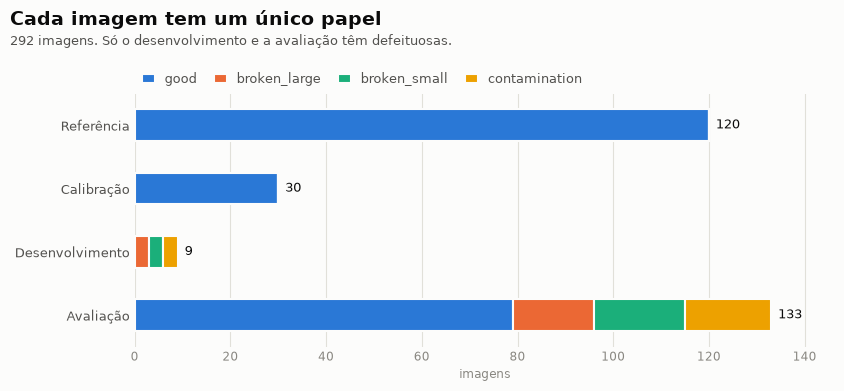

In [ ]:
fig = viz.stacked_hbar(tabela, title='Cada imagem tem um único papel',
                       subtitle='292 imagens. Só o desenvolvimento e a avaliação têm defeituosas.')

In [ ]:
# Conferência do critério 1, direto no CSV
boas_treino = (part.split == 'train') & (part.label == 0)
print('Imagens:', len(part), '| sample_id repetido:', int(part.sample_id.duplicated().sum()))
print('Referência e calibração fora das boas do treino:', int((part.role.isin(['reference', 'calibration']) & ~boas_treino).sum()))
print('Boas no desenvolvimento:', int(((part.role == 'development') & (part.label == 0)).sum()))
aval = part[part.role == 'evaluation']
print('Boas da avaliação por origem:', aval[aval.label == 0].split.value_counts().to_dict())

Imagens: 292 | sample_id repetido: 0
Referência e calibração fora das boas do treino: 0
Boas no desenvolvimento: 0
Boas da avaliação por origem: {'train': 59, 'test': 20}


### Composição dos folds da validação cruzada

`folds.csv` guarda, para cada semente, o fold em que cada imagem da avaliação fica no **teste**. Primeiro os 5 folds da semente 0, depois o mínimo e o máximo nas 25 rodadas (5 folds × 5 sementes).

In [ ]:
f = folds.merge(part[['sample_id', 'defect_type']], on='sample_id')
por_fold = f.groupby(['seed', 'fold', 'defect_type']).size().unstack()[TIPOS]
por_fold.columns.name = None

semente0 = por_fold.loc[0].rename(index=lambda k: f'fold {k}')
semente0.assign(total=semente0.sum(axis=1))

,good,broken_large,broken_small,contamination,total
fold,,,,,
fold 0,16,4,3,4,27
fold 1,16,3,4,4,27
fold 2,16,3,4,4,27
fold 3,16,3,4,3,26
fold 4,15,4,4,3,26


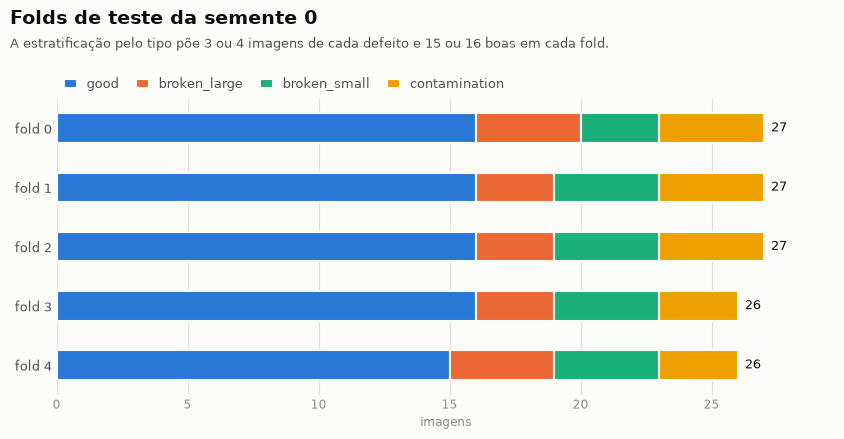

In [ ]:
fig = viz.stacked_hbar(semente0, title='Folds de teste da semente 0',
                       subtitle='A estratificação pelo tipo põe 3 ou 4 imagens de cada defeito e 15 ou 16 boas em cada fold.')

In [ ]:
resumo_folds = por_fold.agg(['min', 'max']).rename(index={'min': 'mínimo por fold de teste', 'max': 'máximo por fold de teste'})
resumo_folds['total'] = [por_fold.sum(axis=1).min(), por_fold.sum(axis=1).max()]
print('Rodadas:', len(por_fold), '| vezes que cada imagem fica no teste, por semente:',
      sorted(folds.groupby(['seed', 'sample_id']).size().unique().tolist()))
resumo_folds

Rodadas: 25 | vezes que cada imagem fica no teste, por semente: [1]


,good,broken_large,broken_small,contamination,total
mínimo por fold de teste,15,3,3,3,26
máximo por fold de teste,16,4,4,4,27


### Nota: as boas do teste são mais claras que as do treino

Ao conferir a partição, vimos que as 20 boas da pasta `test` são cerca de 2 níveis de cinza mais claras que as boas da pasta `train`, provavelmente por serem de outra sessão de fotos. Como a referência é feita só com boas do treino, essa diferença pode virar falso positivo.

Por isso a avaliação mantém boas das duas origens (59 do treino + 20 do teste) e as fases seguintes reportam os falsos positivos **separados por origem**. O registro da Fase 3 já mostra o efeito (linha de base, fora das decisões):

In [ ]:
f3 = pd.read_csv(cfg['root'] / 'results' / 'fase3' / 'resumo.csv')
boas = f3[(f3.variante == 'baseline') & f3.grupo.isin(['good_train', 'good_test'])].set_index('grupo')
boas = boas[['n', 'fp_frac_mean', 'n_pred_components_mean']].assign(fp_frac_mean=lambda t: 100 * t.fp_frac_mean)
boas.index = boas.index.map({'good_train': 'boas do treino (avaliação)', 'good_test': 'boas do teste (avaliação)'})
boas.columns = ['n', 'pixels falsos positivos (% da garrafa)', 'componentes espúrios por imagem']
viz.fmt_table(boas.sort_index(ascending=False))

,n,pixels falsos positivos (% da garrafa),componentes espúrios por imagem
grupo,,,
boas do treino (avaliação),59,"0,44","23,27"
boas do teste (avaliação),20,"0,92","35,85"


### Exemplo visual (opcional, precisa do dataset)

Mede o brilho médio dentro da garrafa (disco de `stats.object_disk`, 95% do raio, imagem em cinza a 256 px) em todas as boas, por pasta de origem. Com esta medida a diferença fica em 1,6 nível, da mesma ordem do desvio entre imagens. Sem o dataset, a célula avisa e é pulada.

In [ ]:
if viz.dataset_available(cfg['category_dir']):
    import cv2
    from pdi_defeitos.io import list_samples, load_sample
    from pdi_defeitos.reference import circular_roi
    from pdi_defeitos.stats import object_disk

    def brilho(row):
        gray = cv2.cvtColor(load_sample(row, size=cfg['image']['size'])[0], cv2.COLOR_RGB2GRAY)
        cx, cy, r = object_disk(gray)
        return gray[circular_roi(gray.shape, (cx, cy), cfg['reference']['roi_frac'] * r) > 0].mean()

    todas = list_samples(cfg['category_dir'])
    boas_img = todas[todas.defect_type == 'good'].copy()
    boas_img['brilho'] = boas_img.apply(brilho, axis=1)
    b = boas_img.groupby('split').brilho.agg(['count', 'mean', 'std']).loc[['train', 'test']]
    b.index = ['boas do treino', 'boas do teste']
    b.columns = ['n', 'brilho médio (níveis de cinza)', 'desvio entre imagens']
    display(viz.fmt_table(b))
    print('Diferença teste − treino:', viz.fmt_br(b.iloc[1, 1] - b.iloc[0, 1]), 'níveis de cinza')

,n,brilho médio (níveis de cinza),desvio entre imagens
boas do treino,209,"64,03","1,66"
boas do teste,20,"65,66","1,87"


Diferença teste − treino: 1,62 níveis de cinza


## 5. Leitura e decisão

- Os três critérios foram atendidos: um papel por imagem, nenhum vazamento entre papéis e folds de teste com 3 ou 4 imagens de cada defeito e 15 ou 16 boas (26 ou 27 imagens por fold).
- O desenvolvimento tem só 3 imagens por tipo. Ele mostra **direção**, não tamanho de efeito. Por isso as decisões das fases seguintes usam a AUROC de pixel (centenas de milhares de pixels, independe do limiar) e diferenças menores que 0,01 contam como empate.
- Na validação cruzada, cada fold de teste tem 3 ou 4 exemplos por defeito. Os resultados serão reportados como média ± desvio nas 25 rodadas, e diferenças menores que o desvio não contam como ganho.

**Decisão:** a partição com semente 0 fica congelada em `results/fase2/particao.csv`. Os parâmetros são os da seção `partition` do `config.yaml`, mostrados no item 3.

## 6. Como isso orienta a próxima fase

- **Fase 3:** a média e o desvio por pixel saem só das 120 imagens de referência; o limiar sai só das 30 de calibração; as comparações usam as 9 de desenvolvimento.
- A avaliação (133 imagens) fica intocada até os experimentos finais. Quando aparecer antes disso, é só como registro, marcado como "não usado para decidir".
- Falsos positivos nas boas sempre separados em treino e teste.